# 02 — Shape: how does the daily price curve look, and how has it changed?

**Method:** median price by hour of day (from interval start, NEM time), split by season and year.
Median, not mean, so a handful of $15,000+ intervals don't drag the whole hour up; spikes are Analysis 2 and 4.

**Season-years.** Australian seasons straddle financial years (winter Jun–Aug crosses 1 July), so each line is one
complete season rather than an FY:
- Summer = Dec–Feb, labelled by the summer, e.g. *2021–22* = Dec 2021 to Feb 2022 (= the FY22 summer)
- Winter, autumn, spring = the calendar year they fall in

Only complete seasons (all 3 months present) are plotted. The June 2022 suspension is excluded.

**What to look for:** the midday collapse deepening each year (the duck curve) and the timing of the evening peak.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_parquet("../data/clean/nem_5min.parquet")
df = df[~df["is_suspension"]].copy()

# Season-year: December belongs to the summer that ends in February of the next year
df["season_year"] = df["interval_start"].dt.year + (df["month"] == 12)

# Keep complete seasons only (3 distinct months), e.g. drops spring 2021 (no Sep 2021) and spring 2026 (Sep only)
months_present = df.groupby(["season", "season_year"])["month"].nunique()
complete = months_present[months_present == 3].index
df = df.set_index(["season", "season_year"]).loc[complete].reset_index()

months_present.unstack("season")

season,autumn,spring,summer,winter
season_year,,,,
2021,NaN,2.0,NaN,NaN
2022,3.0,3.0,3.0,3.0
2023,3.0,3.0,3.0,3.0
2024,3.0,3.0,3.0,3.0
2025,3.0,3.0,3.0,3.0
2026,3.0,1.0,3.0,3.0


In [2]:
shape = df.groupby(["REGIONID", "season", "season_year", "hour"])["RRP"].median()
shape.loc["NSW1", "summer"].unstack("season_year").round(0)

season_year,2022,2023,2024,2025,2026
hour,,,,,
0,80.0,109.0,65.0,88.0,78.0
1,72.0,99.0,63.0,88.0,74.0
2,70.0,90.0,63.0,87.0,73.0
3,70.0,91.0,61.0,88.0,73.0
4,75.0,106.0,64.0,94.0,78.0
5,78.0,110.0,68.0,100.0,73.0
6,67.0,80.0,54.0,60.0,39.0
7,60.0,61.0,45.0,50.0,34.0
8,63.0,51.0,50.0,36.0,22.0


## Chart style

One blue ramp, light → dark = old → recent, so "deepening each year" reads as the line getting darker *and* lower.
Each season-year keeps the same colour in every panel (summer 2021–22 is season_year 2022).
Colours and style live in `src/chart_style.py` so every notebook matches.

In [3]:
import sys
sys.path.append("../src")
from chart_style import apply_style, save_chart, YEAR_COLOR, INK_2, AXIS

apply_style()


def year_label(season, year):
    return f"{year - 1}–{str(year)[2:]}" if season == "summer" else str(year)


def plot_shape(region, seasons=("summer", "winter")):
    """Median price by hour, one line per season-year, one panel per season."""
    ncols = min(2, len(seasons))
    nrows = -(-len(seasons) // ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(5.5 * ncols, 3.8 * nrows), sharey=True, squeeze=False)

    for ax, season in zip(axes.flat, seasons):
        lines = shape.loc[(region, season)].unstack("season_year")
        years = list(lines.columns)
        for year in years:
            ax.plot(lines.index, lines[year], color=YEAR_COLOR[year], lw=2, label=year_label(season, year))
        ax.axhline(0, color=AXIS, lw=1)
        ax.set_title(season.capitalize())
        ax.set_xticks(range(0, 24, 3), [f"{h:02d}:00" for h in range(0, 24, 3)])
        ax.set_xlim(0, 23)
        ax.set_xlabel("Hour of day (NEM time, interval start)")
        # Legend in one row under the panel, so it never sits on top of a line
        ax.legend(frameon=False, fontsize=9, labelcolor=INK_2, ncol=len(years), handlelength=1.5,
                  columnspacing=1.2, loc="upper left", bbox_to_anchor=(0, -0.2))
    for ax in axes[:, 0]:
        ax.set_ylabel("Median price ($/MWh)")
    for ax in axes.flat[len(seasons):]:
        ax.set_visible(False)

    fig.suptitle(f"{region}: median price by hour of day", x=0.01, ha="left", fontsize=13, fontweight="semibold")
    fig.tight_layout()
    return fig

## 1. NSW1 — summer vs winter

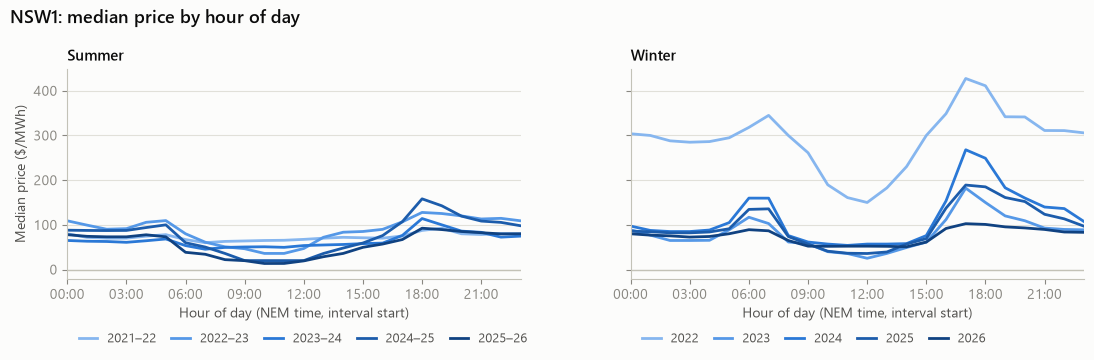

In [4]:
fig = plot_shape("NSW1")
save_chart(fig, "../charts/02_shape_nsw1.png")

**What it shows:** _your sentence_

**Why it matters to a trader:** _your sentence_

## 2. SA1 — summer vs winter

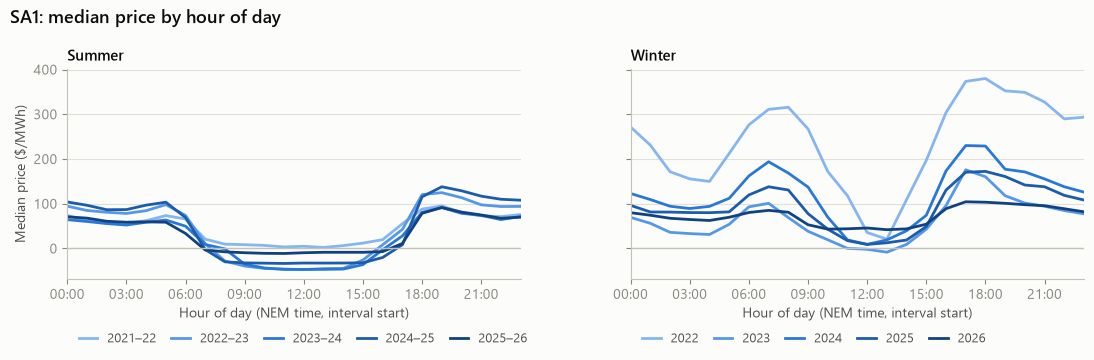

In [5]:
fig = plot_shape("SA1")
save_chart(fig, "../charts/02_shape_sa1.png")

**What it shows:** _your sentence_

**Why it matters to a trader:** _your sentence_

## 3. All four seasons

Spring usually has the deepest midday trough: strong solar, mild temperatures, low demand.

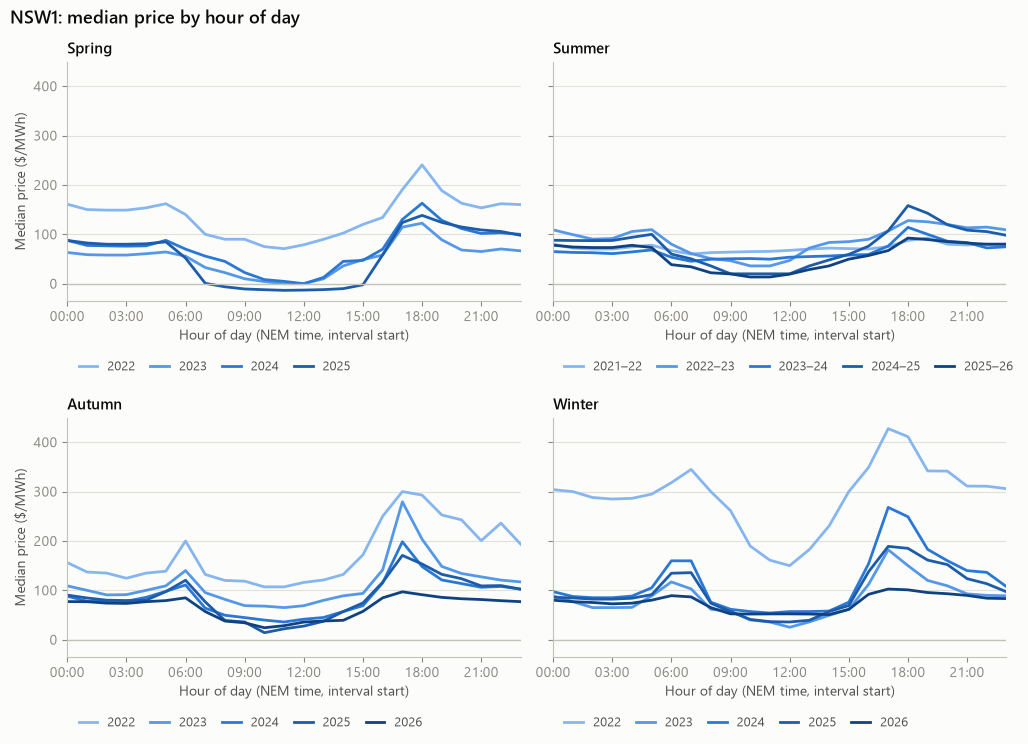

In [6]:
fig = plot_shape("NSW1", ["spring", "summer", "autumn", "winter"])
save_chart(fig, "../charts/02_shape_nsw1_all_seasons.png")

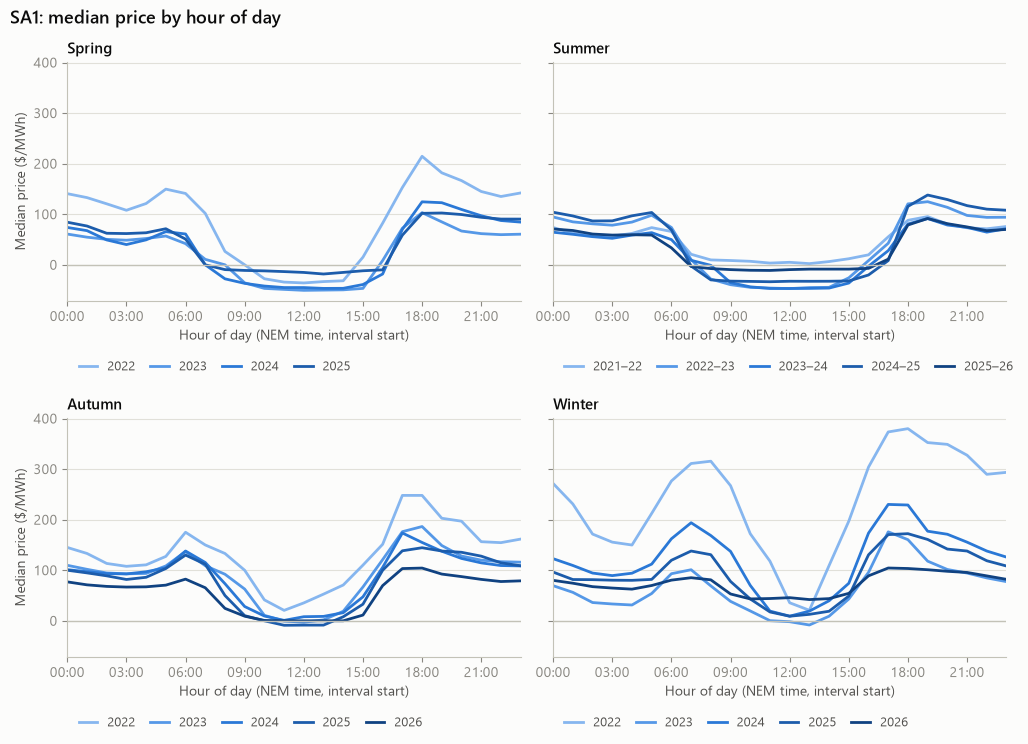

In [7]:
fig = plot_shape("SA1", ["spring", "summer", "autumn", "winter"])
save_chart(fig, "../charts/02_shape_sa1_all_seasons.png")

## 4. The numbers behind the shape

Medians over the intervals in each window (interval start, NEM time):
- **midday** = 10:00–14:55, **evening** = 17:00–20:55
- **spread** = evening − midday: roughly what a 4-hour battery earns per MWh cycled, before losses
- **peak_hour** = hour with the highest median price

In [8]:
def window_median(g, start, end):
    return g.loc[g["hour"].between(start, end), "RRP"].median()


def shape_stats(g):
    hourly = g.groupby("hour")["RRP"].median()
    midday, evening = window_median(g, 10, 14), window_median(g, 17, 20)
    return pd.Series({
        "midday": midday,
        "evening": evening,
        "spread": evening - midday,
        "peak_hour": hourly.idxmax(),
        "trough_hour": hourly.idxmin(),
    })


stats = df.groupby(["REGIONID", "season", "season_year"])[["hour", "RRP"]].apply(shape_stats)
stats["peak_hour"] = stats["peak_hour"].astype(int)
stats["trough_hour"] = stats["trough_hour"].astype(int)
stats.round(1)

midday  evening  spread  peak_hour  trough_hour
REGIONID season season_year                                                 
NSW1     autumn 2022          119.0    274.4   155.4         17           10
                2023           69.5    169.9   100.4         17           11
                2024           44.5    136.4    91.9         17           11
                2025           36.5    140.8   104.3         17           10
                2026           36.6     88.9    52.3         17           10
         spring 2022           86.3    193.5   107.2         18           11
                2023           10.0     99.5    89.5         18           12
                2024           11.3    130.0   118.7         18           12
                2025          -12.0    125.6   137.6         18           11
         summer 2022           69.0     83.0    14.0         19            7
                2023           62.0    120.0    58.0         18           10
                2024           53.8     91.5    37.7         18            7
                2025           36.0    131.7    95.7         18           11
                2026           22.1     84.5    62.4         18           10
         winter 2022          183.9    372.0   188.1         17           12
                2023           36.1    137.2   101.1         17           12
                2024           57.0    207.1   150.1         17           11
                2025           40.2    171.0   130.7         17           12
                2026           52.0     97.6    45.7         17           14
SA1      autumn 2022           44.5    233.3   188.8         18           11
                2023            5.5    159.5   154.0         18           12
                2024            8.8    138.3   129.6         17           11
                2025           -0.0    138.0   138.0         18           11
                2026            0.0     97.1    97.1         18           13
         spring 2022          -33.2    180.0   213.2         18           12
                2023          -49.2     82.4   131.6         18           12
                2024          -45.0    110.2   155.2         18           13
                2025          -14.0     94.4   108.4         19           13
         summer 2022            5.4     79.7    74.3         19           13
                2023          -45.8    111.8   157.7         19           12
                2024          -46.5     74.4   120.8         19           11
                2025          -32.7    113.1   145.8         19           11
                2026           -9.5     73.5    83.0         19           11
         winter 2022           98.1    361.3   263.3         18           13
                2023            0.5    137.8   137.2         17           13
                2024           29.8    200.0   170.2         17           12
                2025           19.0    165.7   146.7         18           12
                2026           43.2    101.0    57.8         17           13

In [9]:
# Midday median by season-year: is the trough getting deeper?
stats["midday"].unstack("season_year").round(1)

season_year       2022  2023  2024  2025  2026
REGIONID season                               
NSW1     autumn  119.0  69.5  44.5  36.5  36.6
         spring   86.3  10.0  11.3 -12.0   NaN
         summer   69.0  62.0  53.8  36.0  22.1
         winter  183.9  36.1  57.0  40.2  52.0
SA1      autumn   44.5   5.5   8.8  -0.0   0.0
         spring  -33.2 -49.2 -45.0 -14.0   NaN
         summer    5.4 -45.8 -46.5 -32.7  -9.5
         winter   98.1   0.5  29.8  19.0  43.2

## 5. Five years, day by day

Daily time-weighted average price, Oct 2021 – Sep 2026, with a 30-day rolling average on top.
This uses **all** intervals (the June 2022 suspension is shaded rather than removed, so the crisis is visible).

A handful of spike days average several thousand $/MWh and would flatten everything else, so the y-axis is
**clipped at `CLIP`**: days above it are drawn as triangles on the top edge, with their true value in the table below.
The numbered markers are the five case-study events from `05_spikes`.

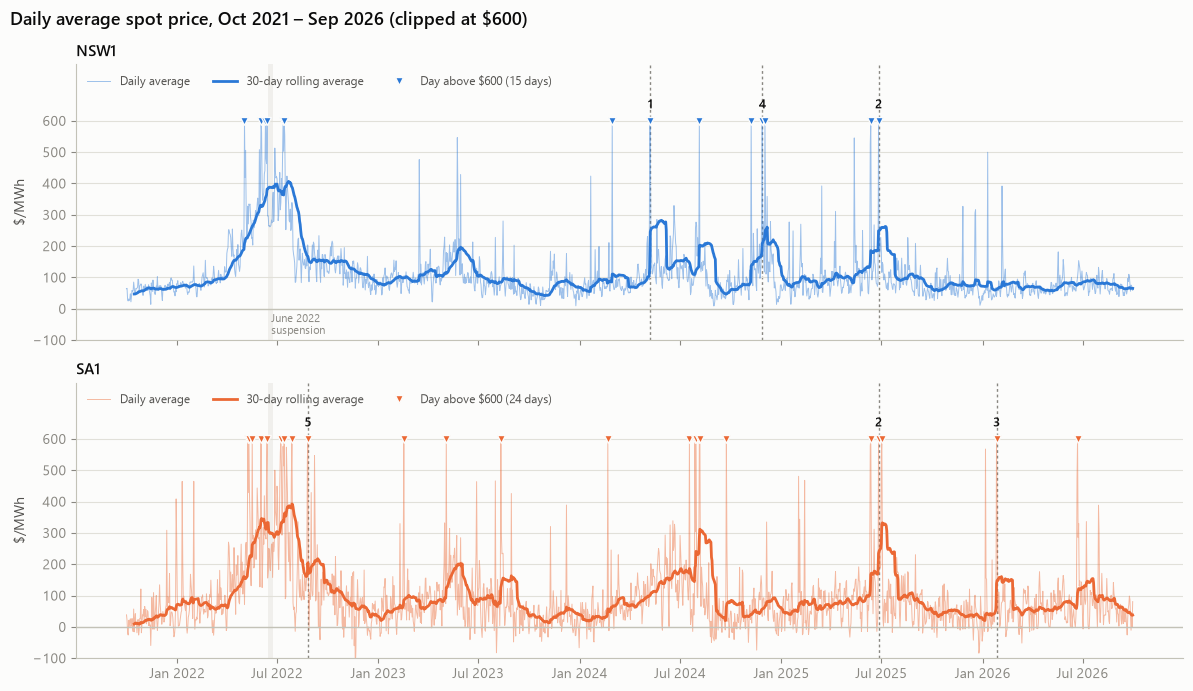

In [10]:
from chart_style import REGION_COLOR, MUTED, INK, SURFACE
import matplotlib.dates as mdates

full_df = pd.read_parquet("../data/clean/nem_5min.parquet")  # includes the suspension
daily = full_df.groupby(["REGIONID", "date"])["RRP"].mean().unstack("REGIONID")
rolling = daily.rolling(30, min_periods=15).mean()

CLIP = 600  # $/MWh
SUSPENSION = (pd.Timestamp("2022-06-15"), pd.Timestamp("2022-06-24"))
EVENTS_MARKED = [  # (number, date, regions) - the five case studies
    (1, "2024-05-08", ["NSW1"]),
    (2, "2025-06-26", ["NSW1", "SA1"]),
    (3, "2026-01-26", ["SA1"]),
    (4, "2024-11-27", ["NSW1"]),
    (5, "2022-08-26", ["SA1"]),
]

fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True, sharey=True)
for ax, region in zip(axes, ["NSW1", "SA1"]):
    d, r = daily[region], rolling[region]
    ax.axvspan(*SUSPENSION, color="#f0efec", lw=0, zorder=0)
    ax.plot(d.index, d.clip(upper=CLIP), color=REGION_COLOR[region], lw=0.7, alpha=0.45, label="Daily average")
    ax.plot(r.index, r, color=REGION_COLOR[region], lw=2, label="30-day rolling average")

    over = d[d > CLIP]
    ax.plot(over.index, [CLIP] * len(over), "v", ms=6, color=REGION_COLOR[region], mec=SURFACE, mew=1,
            clip_on=False, label=f"Day above ${CLIP} ({len(over)} days)")

    for number, day, regions in EVENTS_MARKED:
        if region in regions:
            ax.axvline(pd.Timestamp(day), color=MUTED, lw=1, ls=(0, (2, 2)), zorder=1)
            ax.annotate(str(number), (pd.Timestamp(day), CLIP), xytext=(0, 9), textcoords="offset points",
                        ha="center", fontsize=9, fontweight="semibold", color=INK, annotation_clip=False)

    ax.axhline(0, color=AXIS, lw=1)
    # Headroom above the clip line holds the legend, so it never covers the data
    ax.set_ylim(-100, CLIP * 1.3)
    ax.set_yticks(range(-100, CLIP + 1, 100))
    ax.set_ylabel("$/MWh")
    ax.set_title(region)
    ax.legend(frameon=False, fontsize=8.5, labelcolor=INK_2, loc="upper left", ncol=3)

axes[0].text(SUSPENSION[0], -90, " June 2022\n suspension", fontsize=8, color=MUTED, va="bottom")
axes[-1].xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 7]))
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
fig.suptitle(f"Daily average spot price, Oct 2021 – Sep 2026 (clipped at ${CLIP})",
             x=0.01, ha="left", fontsize=13, fontweight="semibold")
fig.tight_layout()
save_chart(fig, "../charts/02_daily_price.png")

In [11]:
# The days above the clip, with their true daily average
over_clip = daily.stack().rename("daily_average").reset_index()
over_clip = over_clip[over_clip["daily_average"] > CLIP].sort_values("daily_average", ascending=False)
over_clip.style.format({"daily_average": "{:,.0f}", "date": "{:%Y-%m-%d}"}).hide(axis="index")

date,REGIONID,daily_average
2024-05-08,NSW1,"3,554"
2026-01-26,SA1,"2,457"
2024-08-05,NSW1,"2,145"
2025-07-02,SA1,"1,999"
2025-06-26,SA1,"1,970"
2025-06-26,NSW1,"1,951"
2025-06-12,NSW1,"1,694"
2024-11-07,NSW1,"1,650"
2025-06-12,SA1,"1,636"
2024-08-05,SA1,"1,636"


**What it shows:** _your sentence_

**Why it matters to a trader:** _your sentence_

## Try it yourself

- Swap `median` for `mean` in `shape` and re-run: what happens to the evening peak, and why?
- Change the windows in `shape_stats` (e.g. midday 11–14) and see how sensitive the spread is
- Split by `is_weekend`: is the weekend midday trough deeper?